In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy


In [12]:
dataframe = pd.read_csv('../data/cell2cell_raw.csv')

In [13]:
display(dataframe.head(10))

,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,...,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000002,Yes,24.00,219.0,22.0,0.25,0.0,0.0,-157.0,-19.0,...,0,4,No,0,30,Yes,1-Highest,Suburban,Professional,No
1,3000010,Yes,16.99,10.0,17.0,0.00,0.0,0.0,-4.0,0.0,...,0,5,No,0,30,No,4-Medium,Suburban,Professional,Yes
2,3000014,No,38.00,8.0,38.0,0.00,0.0,0.0,-2.0,0.0,...,0,6,No,0,Unknown,No,3-Good,Town,Crafts,Yes
3,3000022,No,82.28,1312.0,75.0,1.24,0.0,0.0,157.0,8.1,...,0,6,No,0,10,No,4-Medium,Other,Other,No
4,3000026,Yes,17.14,0.0,17.0,0.00,0.0,0.0,0.0,-0.2,...,0,9,No,1,10,No,1-Highest,Other,Professional,Yes
5,3000030,No,38.05,682.0,52.0,0.25,0.0,0.0,148.0,-3.1,...,0,1,No,1,30,No,3-Good,Other,Other,Yes
6,3000038,No,31.66,26.0,30.0,0.25,0.0,0.0,60.0,4.0,...,0,9,No,1,30,No,1-Highest,Other,Self,Yes
7,3000042,No,62.13,98.0,66.0,2.48,0.0,0.0,24.0,6.8,...,0,6,No,0,30,No,1-Highest,Other,Professional,No
8,3000046,No,35.30,24.0,35.0,0.00,0.0,0.0,20.0,-0.3,...,0,9,No,0,80,No,1-Highest,Other,Other,Yes
9,3000050,No,81.00,1056.0,75.0,0.00,0.0,0.0,43.0,2.4,...,0,5,No,1,30,No,3-Good,Other,Professional,No


In [14]:
# Kiểm tra số lượng và tỷ lệ dữ liệu thiếu của từng feature
total_rows = len(dataframe)

# Chuẩn hóa biến mục tiêu: 1 = rời bỏ, 0 = không rời bỏ.
churn_flag = (
    dataframe['Churn']
    .astype('string')
    .str.strip()
    .str.lower()
    .map({'yes': 1, 'no': 0})
)

if churn_flag.isna().any():
    invalid_targets = dataframe.loc[churn_flag.isna(), 'Churn'].unique()
    raise ValueError(
        f'Phát hiện giá trị Churn chưa được ánh xạ: {invalid_targets}'
    )

# Kiểm tra thiếu dữ liệu ở cấp khách hàng, không cộng trùng một khách hàng
# khi người đó thiếu nhiều feature. Loại ID và target khỏi tập feature.
analysis_features = [
    feature
    for feature in dataframe.columns
    if feature not in ['CustomerID', 'Churn']
]
customer_has_missing = dataframe[analysis_features].isna().any(axis=1)
customers_with_missing_count = int(customer_has_missing.sum())
churn_customers_with_missing_count = int(
    churn_flag.loc[customer_has_missing].sum()
)
non_churn_customers_with_missing_count = (
    customers_with_missing_count - churn_customers_with_missing_count
)
churn_rate_among_customers_with_missing = (
    churn_customers_with_missing_count / customers_with_missing_count
    if customers_with_missing_count > 0
    else np.nan
)

missing_churn_count = [
    int(churn_flag.loc[dataframe[feature].isna()].sum())
    for feature in dataframe.columns
]

missing_summary = pd.DataFrame({
    'feature': dataframe.columns,
    'dtype': dataframe.dtypes.astype(str).to_numpy(),
    'missing_count': dataframe.isna().sum().to_numpy(),
    'non_missing_count': dataframe.notna().sum().to_numpy(),
    'churn_count_among_missing': missing_churn_count,
})

missing_summary['missing_pct'] = (
    missing_summary['missing_count'] / total_rows * 100
)
missing_summary['churn_rate_among_missing_pct'] = (
    missing_summary['churn_count_among_missing']
    .div(missing_summary['missing_count'])
    .mul(100)
    .where(missing_summary['missing_count'].gt(0))
)

# Sắp xếp feature thiếu nhiều nhất lên đầu; tên feature dùng để phá hòa.
missing_summary = missing_summary.sort_values(
    by=['missing_count', 'feature'],
    ascending=[False, True],
).reset_index(drop=True)

print(f'Tổng số dòng: {total_rows:,}')
print(f'Tổng số feature: {dataframe.shape[1]:,}')
print(f'Tỷ lệ churn toàn bộ dữ liệu: {churn_flag.mean():.2%}')
print(
    'Tổng số khách hàng thiếu ít nhất một feature: '
    f'{customers_with_missing_count:,}'
)
print(
    'Trong số khách hàng thiếu dữ liệu, số người churn: '
    f'{churn_customers_with_missing_count:,}'
)
print(
    'Trong số khách hàng thiếu dữ liệu, số người không churn: '
    f'{non_churn_customers_with_missing_count:,}'
)
print(
    'Tỷ lệ churn trong nhóm khách hàng thiếu dữ liệu: '
    f'{churn_rate_among_customers_with_missing:.2%}'
)
print(
    'Số feature có dữ liệu thiếu: '
    f"{(missing_summary['missing_count'] > 0).sum():,}"
)

display(
    missing_summary.style
    .format({
        'missing_pct': '{:.2f}%',
        'churn_rate_among_missing_pct': '{:.2f}%',
    }, na_rep='N/A')
    .background_gradient(
        subset=[
            'missing_count',
            'missing_pct',
            'churn_rate_among_missing_pct',
        ],
        cmap='Reds',
    )
)

# Lưu ý: isna() phát hiện NaN/None. Các mã văn bản như 'Unknown'
# chưa được coi là thiếu và nên được kiểm tra riêng theo data dictionary.

Tổng số dòng: 51,047
Tổng số feature: 58
Tỷ lệ churn toàn bộ dữ liệu: 28.82%
Tổng số khách hàng thiếu ít nhất một feature: 1,295
Trong số khách hàng thiếu dữ liệu, số người churn: 466
Trong số khách hàng thiếu dữ liệu, số người không churn: 829
Tỷ lệ churn trong nhóm khách hàng thiếu dữ liệu: 35.98%
Số feature có dữ liệu thiếu: 14


,feature,dtype,missing_count,non_missing_count,churn_count_among_missing,missing_pct,churn_rate_among_missing_pct
0,AgeHH1,float64,909,50138,249,1.78%,27.39%
1,AgeHH2,float64,909,50138,249,1.78%,27.39%
2,PercChangeMinutes,float64,367,50680,208,0.72%,56.68%
3,PercChangeRevenues,float64,367,50680,208,0.72%,56.68%
4,DirectorAssistedCalls,float64,156,50891,70,0.31%,44.87%
5,MonthlyMinutes,float64,156,50891,70,0.31%,44.87%
6,MonthlyRevenue,float64,156,50891,70,0.31%,44.87%
7,OverageMinutes,float64,156,50891,70,0.31%,44.87%
8,RoamingCalls,float64,156,50891,70,0.31%,44.87%
9,TotalRecurringCharge,float64,156,50891,70,0.31%,44.87%


MonthlyRevenue               TotalRecurringCharge                \
               count median   mean                count median   mean   
Churn                                                                   
No               743  52.33  64.79                  743   45.0  49.53   
Yes              396  45.08  62.38                  396   40.0  41.15   

      MonthsInService                
                count median   mean  
Churn                                
No                829   15.0  19.37  
Yes               466   18.0  20.38

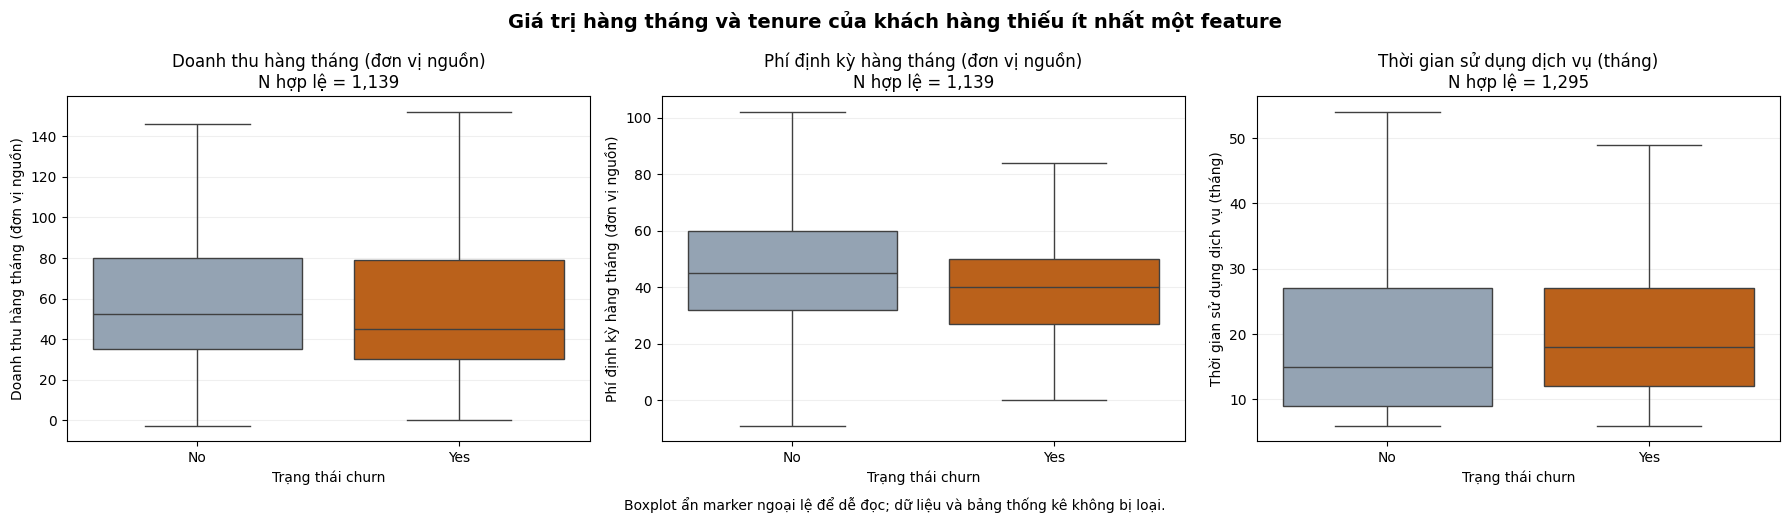

,metric,customer_count
0,Khách hàng thiếu dữ liệu doanh thu/phí,156
1,Trong đó churn,70
2,Trong đó không churn,86


,count,median,mean,min,max
Churn,,,,,
No,86,29.0,34.14,14,60
Yes,70,27.5,28.99,8,59


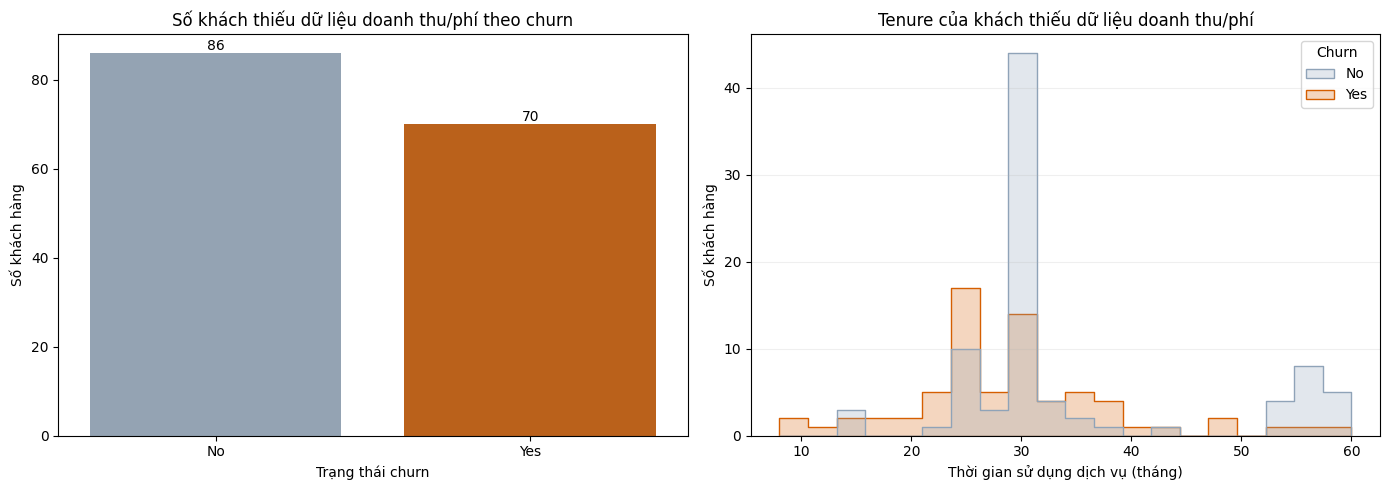

Lưu ý: không thể suy ra mức tiền của khách hàng tại những ô bị thiếu. Biểu đồ đầu chỉ dùng các giá trị còn quan sát được; biểu đồ sau mô tả tenure của nhóm thiếu MonthlyRevenue hoặc TotalRecurringCharge.


In [15]:
# Trực quan giá trị hàng tháng và tenure trong nhóm khách hàng thiếu dữ liệu
focus_features = [
    'MonthlyRevenue',
    'TotalRecurringCharge',
    'MonthsInService',
]
feature_labels = {
    'MonthlyRevenue': 'Doanh thu hàng tháng (đơn vị nguồn)',
    'TotalRecurringCharge': 'Phí định kỳ hàng tháng (đơn vị nguồn)',
    'MonthsInService': 'Thời gian sử dụng dịch vụ (tháng)',
}
churn_order = ['No', 'Yes']
churn_palette = {'No': '#8FA3B8', 'Yes': '#D55E00'}

missing_customer_profile = dataframe.loc[
    customer_has_missing,
    ['Churn', *focus_features],
].copy()

# Bảng số liệu hỗ trợ đọc biểu đồ; count là số quan sát hợp lệ của từng biến.
profile_summary = (
    missing_customer_profile
    .groupby('Churn', observed=True)[focus_features]
    .agg(['count', 'median', 'mean'])
    .round(2)
)
display(profile_summary)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feature in zip(axes, focus_features):
    sns.boxplot(
        data=missing_customer_profile,
        x='Churn',
        y=feature,
        order=churn_order,
        hue='Churn',
        hue_order=churn_order,
        palette=churn_palette,
        legend=False,
        showfliers=False,
        ax=ax,
    )
    valid_count = missing_customer_profile[feature].notna().sum()
    ax.set_title(f'{feature_labels[feature]}\nN hợp lệ = {valid_count:,}')
    ax.set_xlabel('Trạng thái churn')
    ax.set_ylabel(feature_labels[feature])
    ax.grid(axis='y', alpha=0.2)

fig.suptitle(
    'Giá trị hàng tháng và tenure của khách hàng thiếu ít nhất một feature',
    fontsize=14,
    fontweight='bold',
)
fig.text(
    0.5,
    -0.02,
    'Boxplot ẩn marker ngoại lệ để dễ đọc; dữ liệu và bảng thống kê không bị loại.',
    ha='center',
)
plt.tight_layout()
plt.show()

# Tách riêng khách hàng thiếu MonthlyRevenue hoặc TotalRecurringCharge.
financial_features = ['MonthlyRevenue', 'TotalRecurringCharge']
financial_missing_mask = dataframe[financial_features].isna().any(axis=1)
financial_missing_customers = dataframe.loc[
    financial_missing_mask,
    ['CustomerID', 'Churn', *financial_features, 'MonthsInService'],
].copy()

financial_missing_overview = pd.DataFrame({
    'metric': [
        'Khách hàng thiếu dữ liệu doanh thu/phí',
        'Trong đó churn',
        'Trong đó không churn',
    ],
    'customer_count': [
        len(financial_missing_customers),
        financial_missing_customers['Churn'].eq('Yes').sum(),
        financial_missing_customers['Churn'].eq('No').sum(),
    ],
})
display(financial_missing_overview)

tenure_summary_financial_missing = (
    financial_missing_customers
    .groupby('Churn', observed=True)['MonthsInService']
    .agg(['count', 'median', 'mean', 'min', 'max'])
    .round(2)
)
display(tenure_summary_financial_missing)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=financial_missing_customers,
    x='Churn',
    order=churn_order,
    hue='Churn',
    hue_order=churn_order,
    palette=churn_palette,
    legend=False,
    ax=axes[0],
)
axes[0].set_title('Số khách thiếu dữ liệu doanh thu/phí theo churn')
axes[0].set_xlabel('Trạng thái churn')
axes[0].set_ylabel('Số khách hàng')
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='{:,.0f}')

sns.histplot(
    data=financial_missing_customers,
    x='MonthsInService',
    hue='Churn',
    hue_order=churn_order,
    palette=churn_palette,
    bins=20,
    element='step',
    common_norm=False,
    ax=axes[1],
)
axes[1].set_title('Tenure của khách thiếu dữ liệu doanh thu/phí')
axes[1].set_xlabel('Thời gian sử dụng dịch vụ (tháng)')
axes[1].set_ylabel('Số khách hàng')
axes[1].grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()

print(
    'Lưu ý: không thể suy ra mức tiền của khách hàng tại những ô bị thiếu. '
    'Biểu đồ đầu chỉ dùng các giá trị còn quan sát được; biểu đồ sau mô tả tenure '
    'của nhóm thiếu MonthlyRevenue hoặc TotalRecurringCharge.'
)

In [ ]:
# Loại toàn bộ dòng có ít nhất một giá trị thiếu và lưu thành CSV mới
output_path = '../data/cell2cell_complete_cases.csv'

cleaned_dataframe = dataframe.dropna(axis=0, how='any').copy()

original_rows = len(dataframe)
cleaned_rows = len(cleaned_dataframe)
removed_rows = original_rows - cleaned_rows
removed_pct = removed_rows / original_rows if original_rows else 0
remaining_missing = int(cleaned_dataframe.isna().sum().sum())

assert cleaned_dataframe.columns.equals(dataframe.columns), 'Danh sách cột đã bị thay đổi.'
if remaining_missing != 0:
    raise AssertionError(
        f'Dữ liệu sau làm sạch vẫn còn {remaining_missing:,} giá trị thiếu.'
    )

cleaned_dataframe.to_csv(
    output_path,
    index=False,
    encoding='utf-8-sig',
)

print(f'Số dòng ban đầu: {original_rows:,}')
print(f'Số dòng đã loại do thiếu dữ liệu: {removed_rows:,} ({removed_pct:.2%})')
print(f'Số dòng còn lại: {cleaned_rows:,}')
print(f'Số cột giữ lại: {cleaned_dataframe.shape[1]:,}')
print(f'Tổng giá trị thiếu còn lại: {remaining_missing:,}')
print(f'Đã lưu dữ liệu sạch tại: {output_path}')